# Projeto 2: Clustering de Dados e Detecção de Comunidades em Grafos

**Disciplina:** 5954033 - Algoritmos Avançados de Grafos (2026)

**Docente:** Zhao Liang

**Dataset:** Iris

**Integrantes:**

1. Anna Beatriz Souza e Silva - 13694103
2. Milena Rodrigues Monteiro - 12566157


## Etapa 1 - Preparação dos dados

O dataset Iris foi importado do **UC Irvine Machine Learning Repository**. Suas demais descrições e instruções para importar os dados em Python estão presentes [nesse link](https://archive.ics.uci.edu/dataset/53/iris).

Nesse dataset, cada instância corresponde a uma planta, e seus atributos representam certas descrições de cada uma com um valor contínuo em centímetros.

### Instalando bibliotecas necessárias

In [1]:
%pip install --quiet ucimlrepo scikit-learn networkx matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
# get_ipython().kernel.do_shutdown(restart=True)

### Importando os dados

In [3]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# fetch dataset
iris = fetch_ucirepo(id=53)

# dados (em formato de pandas dataframes)
X = iris.data.features
y = iris.data.targets

# Classes reais em vetor 1D (ground truth)
y_gt = np.ravel(y)

### Amostra dos dados

Nessa parte vamos entender os dados que veem no dataset e ver quais são as classes contidas nele.

Considerando aqui, também:

$X$ é um conjunto de dados formado por $n$ objetos:

$$
X = \{x_1, x_2, \ldots, x_n\}
$$

Cada objeto $x_i$ é representado por $d$ atributos (também descritos como colunas aqui):

$$
x_i = (x_{i1}, x_{i2}, \ldots, x_{id})
$$

In [4]:
display(X.sample(5))

,sepal length,sepal width,petal length,petal width
104,6.5,3.0,5.8,2.2
29,4.7,3.2,1.6,0.2
100,6.3,3.3,6.0,2.5
140,6.7,3.1,5.6,2.4
5,5.4,3.9,1.7,0.4


In [5]:
display(y.sample(5))

,class
29,Iris-setosa
87,Iris-versicolor
55,Iris-versicolor
109,Iris-virginica
90,Iris-versicolor


In [6]:
# Mostrando todas as classes únicas possíveis do dataset
display(pd.DataFrame({"class": y["class"].unique()}))

,class
0,Iris-setosa
1,Iris-versicolor
2,Iris-virginica


### Análise das classes em `y`

Como visto na célula acima, existem **3 classes possíveis** em `y`:
- Iris-setosa
- Iris-versicolor
- Iris-virginica

Como elas são as classes categóricas, **elas não serão padronizadas ou normalizadas**, já que representam o *Ground Truth* utilizado quando avaliarmos os agrupamentos.

### Padronização dos atributos em `X`

Além disso, temos as seguintes **colunas** (ou atributos) em `X`:
- `sepal length`
- `sepal width`
- `petal length`
- `petal width`

Como o restante do trabalho calcula distâncias, se um atributo tiver maior escala ou variação, ele pode dominar o resultado. A padronização evita isso.

Isso significa que teremos que padronizar os valores das colunas de `X` utilizando a padronização:

$$
z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}
$$

onde:

- $\mu_j$ é a média do atributo $j$;
- $\sigma_j$ é o desvio-padrão do atributo $j$.

In [7]:
# Média e desvio-padrão de cada coluna
media = X.mean()
desvio_padrao = X.std()

# Padronização: z = (x - média) / desvio-padrão
X_padronizado = (X - media) / desvio_padrao

display(X_padronizado.head())

,sepal length,sepal width,petal length,petal width
0,-0.897674,1.028611,-1.336794,-1.308593
1,-1.139200,-0.124540,-1.336794,-1.308593
2,-1.380727,0.336720,-1.393470,-1.308593
3,-1.501490,0.106090,-1.280118,-1.308593
4,-1.018437,1.259242,-1.336794,-1.308593


## Etapa 2 - Clustering tradicional (Abordagem 1)

Como pontos em um espaço de atributos, utilizando um algoritmo tradicional de clustering.

$$
X \rightarrow C_{\text{cluster}}
$$

O algoritmo recomendado foi o **K-Means**. O objetivo do K-Means é minimizar a soma das distâncias quadráticas entre cada objeto e o centroide do seu cluster.

#### Escolhendo o do número de clusters utilizados $(K)$

De acordo com a descrição do projeto, foram sugeridos:

- Método do cotovelo (**Elbow Method**);
- **Silhouette Score**;
- Conhecimento prévio sobre o dataset.

#### 1. Conhecimento prévio sobre o dataset

Como visto anteriormente, o dataset Iris tem 3 classes, então poderíamos utilizar $K = 3$ como hipótese. Mas podemos confirmar esse valor com os outros dois métodos.

#### 2. Método do cotovelo (**Elbow Method**)

Esse método testa diversos valores de $K$ (nesse caso, de 2 a 10) no K-Means para calcular a inércia (J), a qual mede o quão espalhados os pontos estão dentro de cada cluster, e com qual valor eles começam a ficar menos espalhados.

A inércia é a soma das distâncias quadráticas entre cada ponto e o centróide do seu cluster.

Com o gráfico da variação da inércia, podemos ver um "cotovelo", o qual indicaria o melhor $K$, porque a partir daquele ponto, criar mais clusters praticamente não mudaria muito o resultado.

##### Preparação do ambiente

In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "1" # Evita o aviso de memory leak do KMeans

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Testar valores de K de 2 a 20
valores_k = range(2, 11)

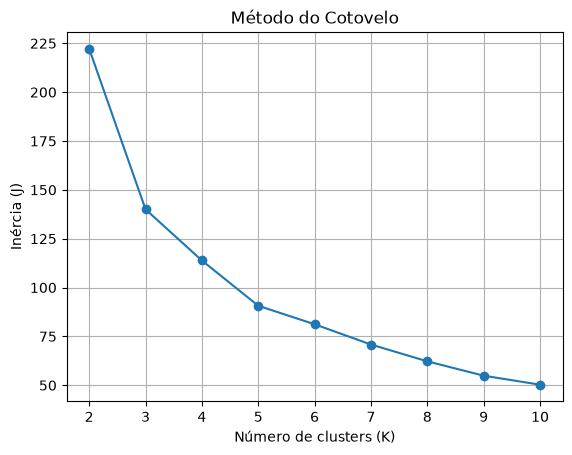

In [10]:
inercia = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    inercia.append(modelo.inertia_)

plt.plot(valores_k, inercia, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (J)")
plt.title("Método do Cotovelo")
plt.grid()
plt.show()

##### Interpretação do método do cotovelo

Observando o gráfico imaginando o formato de um braço, podemos identificar um "cotovelo" (uma dobra) no ponto em que $K = 3$.

Até então, a inércia estava caindo de forma muito brusca, e quando chega em $K = 3$, a queda se suaviza. Por isso, segundo essa métrica, esse seria o número ideal de clusters.

#### 3. Silhouette Score

O Silhouette Score avalia simultaneamente a coesão dos objetos dentro de seus próprios clusters e a separação entre clusters.

Para cada ponto, compara-se a distância média até os pontos do próprio cluster com a distância média até o cluster vizinho mais próximo.

O score varia de -1 a 1: quanto mais próximo de 1, o grupo seria o melhor definido, então ele ajudaria a definir o valor de $K$.

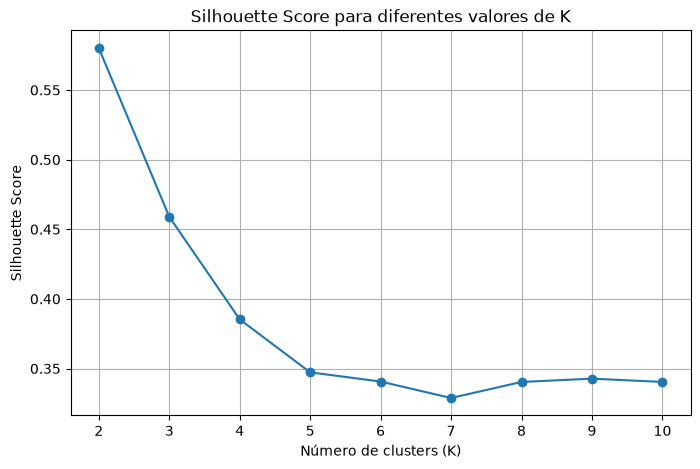

In [11]:
silhouette_scores = []

for k in valores_k:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters_teste = kmeans.fit_predict(X_padronizado)

    score = silhouette_score(
        X_padronizado,
        clusters_teste
    )

    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(
    list(valores_k),
    silhouette_scores,
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score para diferentes valores de K")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

In [12]:
indice_melhor = silhouette_scores.index(max(silhouette_scores))

k_melhor_silhouette = list(valores_k)[indice_melhor]
melhor_score = silhouette_scores[indice_melhor]

print("Melhor K pelo Silhouette Score:", k_melhor_silhouette)
print("Maior Silhouette Score:", melhor_score)

Melhor K pelo Silhouette Score: 2
Maior Silhouette Score: 0.580184463257396


#### Valor de K escolhido

| | Método do cotovelo | Silhouette Score | Conhecimento do dataset |
|---|---|---|---|
| **Valor de $K$** | 3 | 2 | 3 |

Pelos 3 métodos sugeridos, o valor de $K$ que mais se repete é $K = 3$.

O método do cotovelo confirmou a hipótese original, enquanto o Silhouette Score sugere $K = 2$.

### Criando o modelo K-Means

In [27]:
from sklearn.metrics import adjusted_rand_score

K = 3

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_padronizado)
ari_kmeans_real = adjusted_rand_score(y_gt, clusters)

print("K escolhido:", K)
print("Inércia:", kmeans.inertia_)
print("Silhouette Score:", silhouette_score(X_padronizado, clusters))

K escolhido: 3
Inércia: 140.02604451987528
Silhouette Score: 0.4589717867018717


## Etapa 3 - Construção do grafo de similaridade



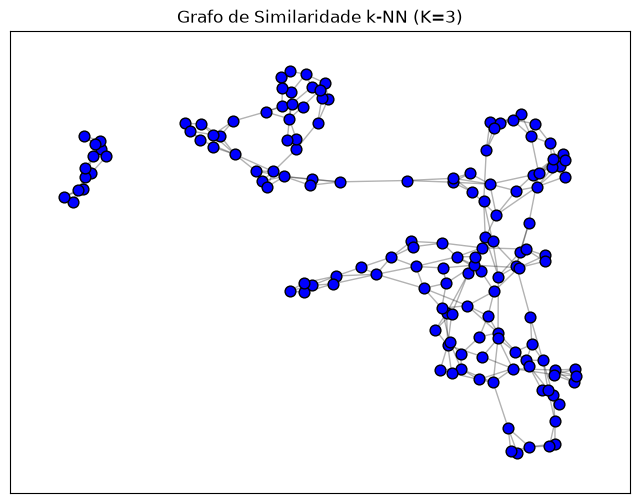

In [28]:
from sklearn.neighbors import kneighbors_graph
import networkx as nx

k_vizinhos = 3

# Cálculo da matriz adjacente utilizando a distância Euclidiana
matriz_adj = kneighbors_graph(X_padronizado, n_neighbors=k_vizinhos, mode="connectivity",
                              metric="euclidean", include_self=False)

# Grafo base
G_base = nx.from_scipy_sparse_array(matriz_adj)

pos = nx.spring_layout(G_base, seed=42)

plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(G_base, pos, node_size=60, node_color="blue", edgecolors="k")
nx.draw_networkx_edges(G_base, pos, alpha=0.3)
plt.title(f"Grafo de Similaridade k-NN (K={k_vizinhos})")
plt.show()

### Pesos das arestas

Utilizando uma função de similaridade Gaussiana para ponderar o grafo:

$$
w_{ij} =
\exp\left(
-\frac{d(x_i,x_j)^2}{2\sigma^2}
\right)
$$

Dessa forma, objetos muito semelhantes terão pesos de conexão maiores.

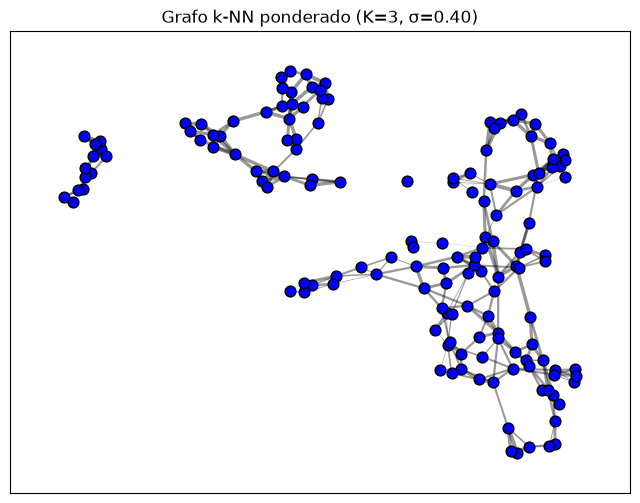

In [46]:
def construir_grafo(X, k):
    # Matriz armazenando as distâncias Euclidianas
    matriz_dist = kneighbors_graph(X, n_neighbors=k, mode="distance",
                                   metric="euclidean", include_self=False)

    # Sigma: média das distâncias das arestas (heurística)
    sigma = matriz_dist.data.mean()

    # Similaridade Gaussiana: w = exp(-d² / (2σ²))
    matriz_pesos = matriz_dist.copy()
    matriz_pesos.data = np.exp(-(matriz_dist.data ** 2) / (2 * sigma ** 2))

    # Grafo ponderado
    return nx.from_scipy_sparse_array(matriz_pesos), sigma

G_peso, sigma = construir_grafo(X_padronizado, k_vizinhos)

# Visualização: espessura proporcional ao peso
pesos = [d["weight"] for _, _, d in G_peso.edges(data=True)]

plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(G_peso, pos, node_size=60, node_color="blue", edgecolors="k")
nx.draw_networkx_edges(G_peso, pos, width=np.array(pesos) * 3, alpha=0.4)
plt.title(f"Grafo k-NN ponderado (K={k_vizinhos}, σ={sigma:.2f})")
plt.show()

## Etapa 4 - Detecção de comunidades

Aplicando um algoritmo de detecção de comunidades dentre as sugestões, o escolhido foi **Label Propagation**.


In [30]:
import random
import numpy as np
from collections import defaultdict, Counter

def label_propagation(G, max_iter=100, seed=42, weight="weight"):
    rng = random.Random(seed)
    labels = {node: node for node in G.nodes()}
    nodes = list(G.nodes())

    for iteracao in range(max_iter):
        rng.shuffle(nodes)
        mudou = False

        for node in nodes:
            vizinhos = list(G.neighbors(node))
            if not vizinhos:
                continue

            contagem = Counter()
            for v in vizinhos:
                peso = G[node][v].get(weight, 1) if weight else 1
                contagem[labels[v]] += peso

            max_votos = max(contagem.values())
            candidatos = [rot for rot, freq in contagem.items() if freq == max_votos]

            if labels[node] in candidatos:
                continue

            labels[node] = rng.choice(candidatos)
            mudou = True

        if not mudou:
            break

    return labels

#### Cálculo das comunidades

In [47]:
# Label Propagation no grafo G
labels_dict = label_propagation(G_base, seed=42)

# Agrupa os vértices por comunidade (maiores primeiro)
grupos = defaultdict(set)
for node, rotulo in labels_dict.items():
    grupos[rotulo].add(node)
comunidades = sorted(grupos.values(), key=len, reverse=True)

# Rótulos 0..n-1 (0 = maior comunidade)
rotulos_comunidades = {v: i for i, com in enumerate(comunidades) for v in com}

# Modularidade
Q = nx.community.modularity(G_base, comunidades, weight="weight")

print(f"Número de comunidades: {len(comunidades)} | Modularidade Q = {Q:.3f}")
for i, com in enumerate(comunidades):
    print(f"  Comunidade {i}: {len(com)} vértices")

Número de comunidades: 32 | Modularidade Q = 0.677
  Comunidade 0: 9 vértices
  Comunidade 1: 8 vértices
  Comunidade 2: 7 vértices
  Comunidade 3: 7 vértices
  Comunidade 4: 7 vértices
  Comunidade 5: 6 vértices
  Comunidade 6: 6 vértices
  Comunidade 7: 6 vértices
  Comunidade 8: 6 vértices
  Comunidade 9: 6 vértices
  Comunidade 10: 6 vértices
  Comunidade 11: 5 vértices
  Comunidade 12: 5 vértices
  Comunidade 13: 5 vértices
  Comunidade 14: 5 vértices
  Comunidade 15: 5 vértices
  Comunidade 16: 5 vértices
  Comunidade 17: 4 vértices
  Comunidade 18: 4 vértices
  Comunidade 19: 4 vértices
  Comunidade 20: 4 vértices
  Comunidade 21: 4 vértices
  Comunidade 22: 3 vértices
  Comunidade 23: 3 vértices
  Comunidade 24: 3 vértices
  Comunidade 25: 3 vértices
  Comunidade 26: 3 vértices
  Comunidade 27: 3 vértices
  Comunidade 28: 2 vértices
  Comunidade 29: 2 vértices
  Comunidade 30: 2 vértices
  Comunidade 31: 2 vértices


#### Visualização do Label Propagation

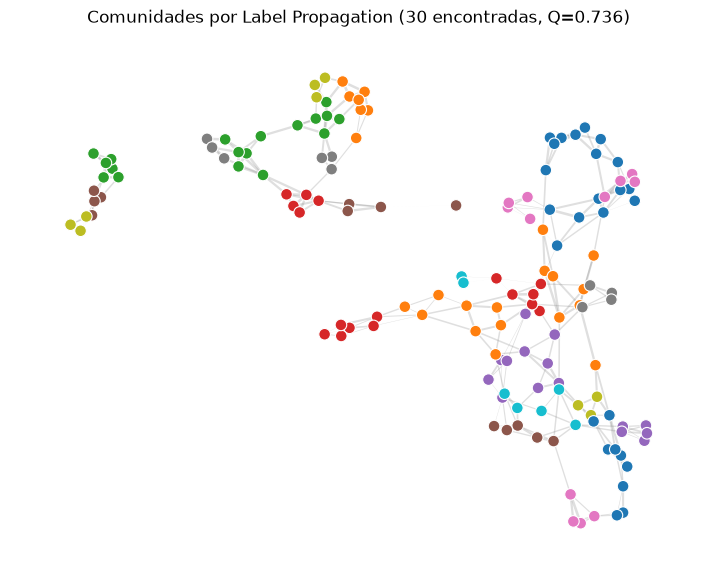

In [42]:
# Visualização
cores = [rotulos_comunidades[v] for v in G_peso.nodes()]
n_com = len(comunidades)
pesos = np.array([d["weight"] for _, _, d in G_peso.edges(data=True)])

plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(G_peso, pos, width=pesos * 2, alpha=0.25, edge_color="gray")
nx.draw_networkx_nodes(G_peso, pos, node_color=cores, cmap="tab10",
                       vmin=0, vmax=max(n_com - 1, 9),
                       node_size=70, edgecolors="white", linewidths=0.8)
plt.title(f"Comunidades por Label Propagation ({n_com} encontradas, Q={Q:.3f})")
plt.axis("off")
plt.show()

### Avaliação por modularidade

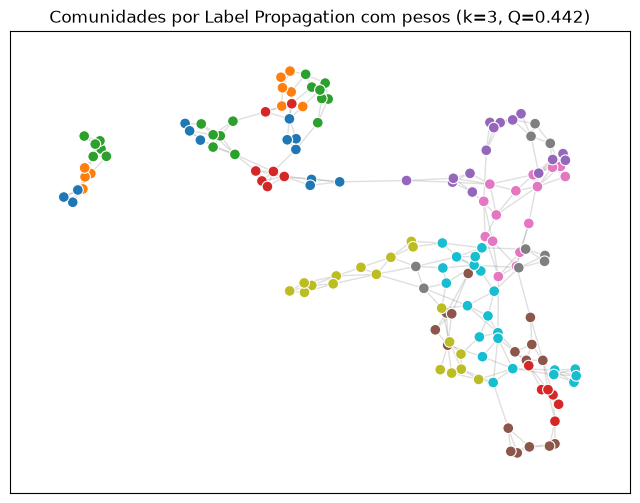

k=3 | Comunidades: 32 | Q=0.442 | ARI(real)=0.102 | ARI(K-Means)=0.101 | Tamanhos: [9, 8, 7, 7, 7, 6, 6, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2]


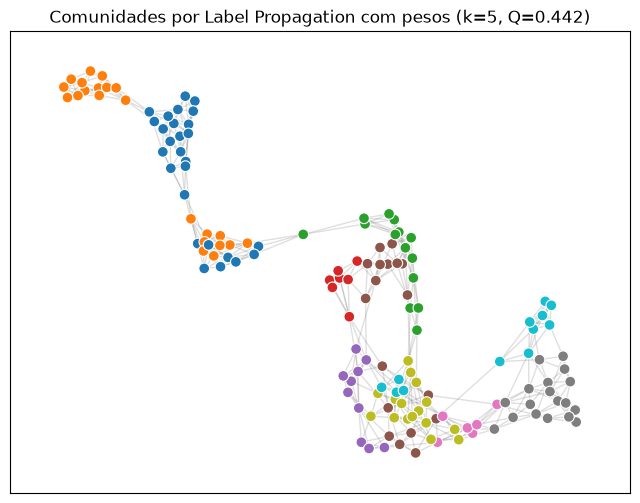

k=5 | Comunidades: 18 | Q=0.442 | ARI(real)=0.214 | ARI(K-Means)=0.215 | Tamanhos: [19, 14, 13, 11, 10, 10, 9, 8, 8, 8, 7, 7, 6, 5, 4, 4, 4, 3]


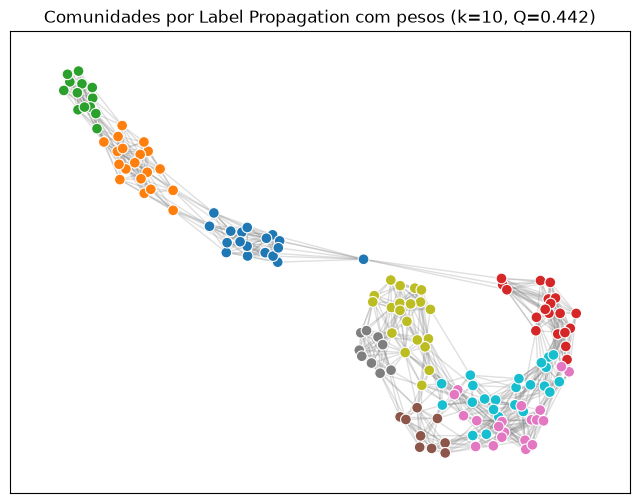

k=10 | Comunidades: 9 | Q=0.442 | ARI(real)=0.340 | ARI(K-Means)=0.332 | Tamanhos: [23, 20, 20, 19, 19, 18, 13, 9, 9]


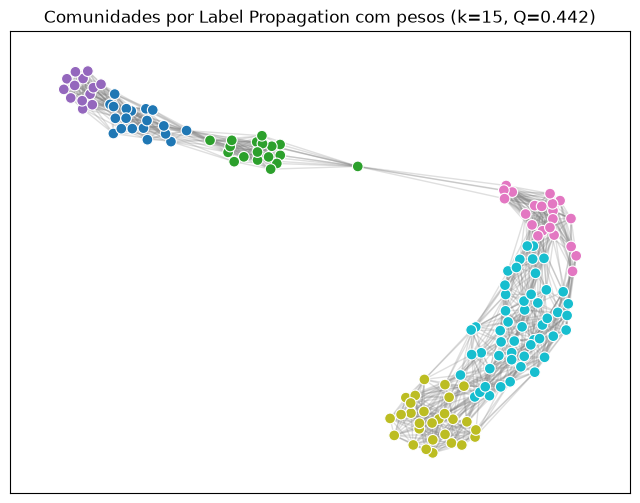

k=15 | Comunidades: 6 | Q=0.442 | ARI(real)=0.387 | ARI(K-Means)=0.409 | Tamanhos: [51, 28, 21, 19, 18, 13]


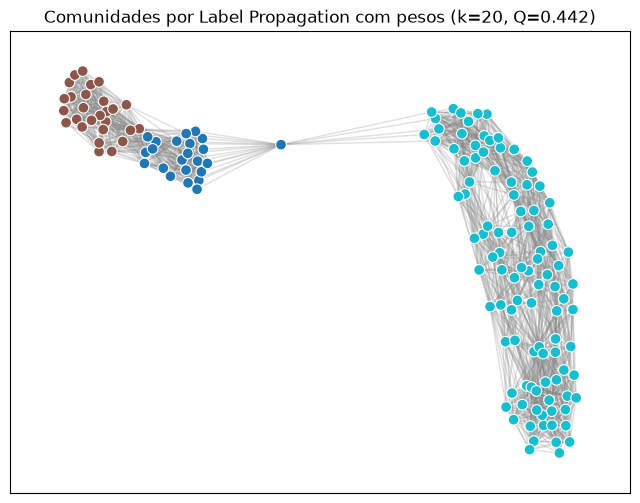

k=20 | Comunidades: 3 | Q=0.442 | ARI(real)=0.440 | ARI(K-Means)=0.442 | Tamanhos: [100, 27, 23]


In [43]:
k_variacoes = [3, 5, 10, 15, 20]
modularidades = {}
ari_lpa_kmeans = {}
ari_lpa_real = {}
num_comunidades_k = {}

for k_var in k_variacoes:
    # Grafo k-NN com pesos (conectividade)
    G_var = nx.from_scipy_sparse_array(
        kneighbors_graph(X_padronizado, n_neighbors=k_var, mode="connectivity",
                         metric="euclidean", include_self=False))

    # Label Propagation sem pesos (cada vizinho vale 1 voto)
    labels_dict_var = label_propagation(G_var, seed=42)

    # Comunidades para a modularidade
    comunidades_dict = defaultdict(set)
    for node, comm in labels_dict_var.items():
        comunidades_dict[comm].add(node)
    comunidades = list(comunidades_dict.values())

    modularidades[k_var] = (
        nx.community.modularity(G_var, comunidades)
        if len(comunidades) > 1 and G_var.number_of_edges() > 0
        else 0.0
    )

    # Formatar rótulos brutos (0..n-1) para calcular o ARI
    rotulos_brutos = [labels_dict_var[i] for i in range(G_var.number_of_nodes())]
    _, lpa_labels_var = np.unique(rotulos_brutos, return_inverse=True)

    num_comunidades_k[k_var] = len(comunidades)
    ari_lpa_kmeans[k_var] = adjusted_rand_score(clusters, lpa_labels_var)
    ari_lpa_real[k_var] = adjusted_rand_score(y_gt, lpa_labels_var)

    # Plot (sem espessura por peso, já que todas as arestas valem 1)
    pos_rede = nx.spring_layout(G_var, seed=42)

    plt.figure(figsize=(8, 6))
    plt.title(f"Comunidades por Label Propagation com pesos (k={k_var}, Q={mod_q:.3f})")
    nx.draw_networkx_edges(G_var, pos=pos_rede, alpha=0.25, edge_color="gray")
    nx.draw_networkx_nodes(G_var, pos=pos_rede, node_color=lpa_labels_var, cmap="tab10",
                           node_size=60, edgecolors="white", linewidths=0.8)
    plt.show()

    tamanhos = sorted(Counter(lpa_labels_var.tolist()).values(), reverse=True)
    print(f"k={k_var} | Comunidades: {num_comunidades_k[k_var]} | Q={mod_q:.3f} | "
          f"ARI(real)={ari_lpa_real[k_var]:.3f} | ARI(K-Means)={ari_lpa_kmeans[k_var]:.3f} | "
          f"Tamanhos: {tamanhos}")

In [44]:
print(np.shape(clusters), np.shape(y_gt))                 # (150,) (150,)
print(np.array_equal(np.ravel(clusters), np.ravel(y_gt))) # deve dar False
print(adjusted_rand_score(y_gt, clusters))                # ~0.62

(150,) (150,)
False
0.6201351808870379


## Etapa 5 - Comparação entre clustering e detecção de comunidades

Comparando a partição obtida pelo clustering:
$
C_{\text{cluster}}
$

Com a partição obtida pela detecção de comunidades:
$
C_{\text{community}}
$

Com a métrica recomendada: **Adjusted Rand Index (ARI)**.

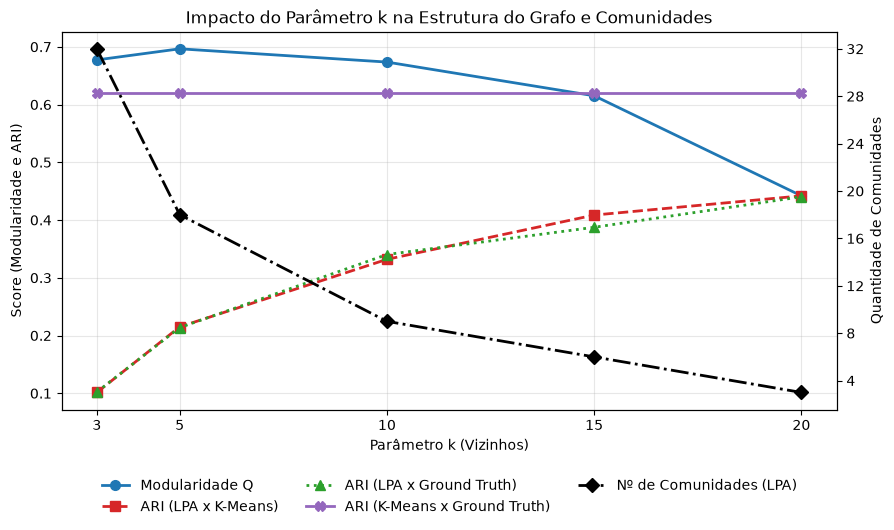

In [45]:
# Gráfico comparativo de métricas
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(k_variacoes, [modularidades[k] for k in k_variacoes], marker="o",
         linestyle="-", color="tab:blue", linewidth=2, markersize=7, label="Modularidade Q")
ax1.plot(k_variacoes, [ari_lpa_kmeans[k] for k in k_variacoes], marker="s", linestyle="--",
         color="tab:red", linewidth=2, markersize=7, label="ARI (LPA x K-Means)")
ax1.plot(k_variacoes, [ari_lpa_real[k] for k in k_variacoes], marker="^", linestyle=":",
         color="tab:green", linewidth=2, markersize=7, label="ARI (LPA x Ground Truth)")
ax1.plot(k_variacoes, [ari_kmeans_real] * len(k_variacoes), marker="X", linestyle="-",
         color="tab:purple", linewidth=2, markersize=7, label="ARI (K-Means x Ground Truth)")

ax1.set_title("Impacto do Parâmetro k na Estrutura do Grafo e Comunidades")
ax1.set_xlabel("Parâmetro k (Vizinhos)")
ax1.set_ylabel("Score (Modularidade e ARI)")
ax1.set_xticks(k_variacoes)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(k_variacoes, [num_comunidades_k[k] for k in k_variacoes], marker="D", 
         linestyle="-.", color="black", linewidth=2, markersize=7, 
         label="Nº de Comunidades (LPA)")
ax2.set_ylabel("Quantidade de Comunidades")
ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

linhas_1, labels_1 = ax1.get_legend_handles_labels()
linhas_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(linhas_1 + linhas_2, labels_1 + labels_2, loc="upper center",
           bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

plt.subplots_adjust(bottom=0.25)
plt.show()

In [22]:
print("ARI (K-Means x Ground Truth):", adjusted_rand_score(np.ravel(y), np.ravel(clusters)))
print("ARI LPA x K-Means:    ", ari_lpa_kmeans)
print("ARI LPA x Ground Truth:", ari_lpa_real)

ARI (K-Means x Ground Truth): 0.6201351808870379
ARI LPA x K-Means:     {3: 0.10144167764407813, 5: 0.21506806077419083, 10: 0.3319379313302159, 15: 0.4086120628287267, 20: 0.4419025901878424}
ARI LPA x Ground Truth: {3: 0.10233647675040843, 5: 0.21374189851745873, 10: 0.3402937235721408, 15: 0.3874526836477703, 20: 0.4402831388889892}


In [23]:
print(np.array_equal(np.ravel(clusters), np.ravel(y)))  # True = são a mesma coisa

False


In [24]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_padronizado)

print("ARI (K-Means x Ground Truth):", adjusted_rand_score(y_gt, clusters))

ARI (K-Means x Ground Truth): 0.6201351808870379


### 1.6. Experimento com diferentes valores de $k$

Os alunos deverão investigar como o valor de $k$ utilizado na construção do grafo influencia o resultado da detecção de comunidades.

Para cada valor de $k$, deverão registrar:

| $k$ | Nº de comunidades | Modularidade $Q$ | NMI/ARI |
| --: | ----------------: | ---------------: | ------: |
|   3 |                 — |                — |       — |
|   5 |                 — |                — |       — |
|  10 |                 — |                — |       — |
|  15 |                 — |                — |       — |
|  20 |                 — |                — |       — |

Os resultados deverão ser apresentados também por meio de gráficos.

Os alunos deverão discutir:

- Como o aumento de $k$ altera a densidade do grafo?
- Como o número de comunidades muda?
- Qual valor de $k$ produz os melhores resultados?
- O que acontece quando $k$ é muito pequeno?
- O que acontece quando $k$ é muito grande?


In [25]:
tabela = pd.DataFrame({
    "k": k_variacoes,
    "Nº de comunidades": [num_comunidades_k[k] for k in k_variacoes],
    "Modularidade Q": [round(modularidades[k], 3) for k in k_variacoes],
    "ARI (LPA x Real)": [round(ari_lpa_real[k], 3) for k in k_variacoes],
    "ARI (LPA x K-Means)": [round(ari_lpa_kmeans[k], 3) for k in k_variacoes],
})

display(tabela.style.hide(axis="index"))

k,Nº de comunidades,Modularidade Q,ARI (LPA x Real),ARI (LPA x K-Means)
3,32,0.677000,0.102000,0.101000
5,18,0.697000,0.214000,0.215000
10,9,0.674000,0.340000,0.332000
15,6,0.615000,0.387000,0.409000
20,3,0.442000,0.440000,0.442000


In [26]:
for k in k_variacoes:
    G_tmp, _ = construir_grafo(X_padronizado, k)
    print(f"k={k} | arestas={G_tmp.number_of_edges()} | densidade={nx.density(G_tmp):.3f}")

k=3 | arestas=301 | densidade=0.027
k=5 | arestas=493 | densidade=0.044
k=10 | arestas=975 | densidade=0.087
k=15 | arestas=1427 | densidade=0.128
k=20 | arestas=1893 | densidade=0.169
